## 1. Giới thiệu & Tải dữ liệu
Tập dữ liệu RT-IoT2022 ghi lại lưu lượng mạng (network traffic) từ các thiết bị IoT thực tế bao gồm hành vi bình thường và các dạng tấn công mạng.

Có thể tải trực tiếp từ UCI thư viện `ucimlrepo` hoặc đọc file `.csv` nếu đã tải về máy.

In [3]:
# Import thư viện pandas để xử lý và thao tác dữ liệu dạng bảng
import pandas as pd

# Import matplotlib.pyplot để vẽ biểu đồ trực quan hóa
import matplotlib.pyplot as plt

# Import seaborn để vẽ các biểu đồ thống kê nâng cao và đẹp mắt hơn
import seaborn as sns 

# Import numpy để thực hiện các tính toán số học
import numpy as np
import os

In [4]:
# Thiết lập giao diện hiển thị biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Tự động tạo thư mục 'figtures' để lưu hình ảnh nếu chưa tồn tại
output_dir = 'figures'
os.makedirs(output_dir, exist_ok=True)
print(f"Thư mục lưu hình ảnh: '{output_dir}/' đã sẵn sàng.")

file_path = '../data/RT_IOT2022'
df = pd.read_csv(file_path)

print("Đọc file thành công!", df.shape)

Thư mục lưu hình ảnh: 'figures/' đã sẵn sàng.
Đọc file thành công! (123117, 85)


In [5]:
# Kiểm tra số lượng dòng và số lượng cột của tập dữ liệu
print(f"Số lượng dòng (instances): {df.shape[0]}")
print(f"Số lượng cột (features): {df.shape[1]}")

# Hiển thị 5 dòng đầu tiên
df.head()

Số lượng dòng (instances): 123117
Số lượng cột (features): 85


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


In [6]:
# Kiểm tra kiểu dữ liệu của các cột
print("--- THÔNG TIN KIỂU DỮ LIỆU ---")
print(df.dtypes.value_counts())

# Kiểm tra tổng số lượng giá trị thiếu (Null/NA)
missing_val = df.isnull().sum().sum()
print(f"\nTổng số giá trị bị thiếu (Missing values): {missing_val}")

--- THÔNG TIN KIỂU DỮ LIỆU ---
float64    56
int64      26
str         3
Name: count, dtype: int64

Tổng số giá trị bị thiếu (Missing values): 0


In [16]:
# Đếm dòng trùng hoàn toàn trên mọi cột
print("Trùng (tính cả Unnamed: 0):", df.duplicated().sum())

# Đếm dòng trùng sau khi bỏ cột Unnamed: 0 (cột chỉ số, nên so sánh bỏ nó đi mới đúng)
df_khong_index = df.drop(columns=['Unnamed: 0'])
print("Trùng (bỏ Unnamed: 0):", df_khong_index.duplicated().sum())

# Xem các dòng trùng thuộc nhãn nào (keep=False đánh dấu mọi dòng thuộc nhóm trùng)
dong_trung = df_khong_index.duplicated(keep=False)
print(df.loc[dong_trung, 'Attack_type'].value_counts())

Trùng (tính cả Unnamed: 0): 0
Trùng (bỏ Unnamed: 0): 5195
Attack_type
DOS_SYN_Hping                 9082
Thing_Speak                    820
ARP_poisioning                 165
Wipro_bulb                      68
NMAP_UDP_SCAN                   10
MQTT_Publish                     5
DDOS_Slowloris                   2
Metasploit_Brute_Force_SSH       2
Name: count, dtype: int64


In [17]:
# Đếm số giá trị khác nhau của từng cột
so_gia_tri = df.nunique()

# Cột chỉ có 1 giá trị thì không mang thông tin
cot_hang = so_gia_tri[so_gia_tri == 1].index.tolist()
print("Số cột hằng:", len(cot_hang))
print(cot_hang)

Số cột hằng: 1
['bwd_URG_flag_count']


In [18]:
# Với mỗi nhãn, xem Unnamed: 0 nhỏ nhất, lớn nhất và số mẫu
# Nếu max = count - 1 ở mọi nhãn thì đây là chỉ số hàng trong từng file nguồn
print(df.groupby('Attack_type')['Unnamed: 0'].agg(['min', 'max', 'count']))

                            min    max  count
Attack_type                                  
ARP_poisioning                0   7749   7750
DDOS_Slowloris                0    533    534
DOS_SYN_Hping                 0  94658  94659
MQTT_Publish                  0   4145   4146
Metasploit_Brute_Force_SSH    0     36     37
NMAP_FIN_SCAN                 0     27     28
NMAP_OS_DETECTION             0   1999   2000
NMAP_TCP_scan                 0   1001   1002
NMAP_UDP_SCAN                 0   2589   2590
NMAP_XMAS_TREE_SCAN           0   2009   2010
Thing_Speak                   0   8107   8108
Wipro_bulb                    0    252    253


In [20]:
# Tần suất từng giá trị của hai cột phân loại
print(df['proto'].value_counts())
print(df['service'].value_counts())

proto
tcp     110427
udp      12633
icmp        57
Name: count, dtype: int64
service
-         102861
dns         9753
mqtt        4132
http        3464
ssl         2663
ntp          121
dhcp          50
irc           43
ssh           28
radius         2
Name: count, dtype: int64


In [7]:
# Xác định cột nhãn/mục tiêu (thường là 'Attack_type' hoặc cột cuối cùng)
target_col = 'Attack_type'

# Thống kê số lượng mẫu theo từng loại hành vi/tấn công
attack_counts = df[target_col].value_counts()
attack_percent = df[target_col].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Số lượng mẫu': attack_counts,
    'Tỷ lệ (%)': attack_percent.round(2)
})

print("--- THỐNG KÊ BIẾN MỤC TIÊU ---")
print(summary_target)

--- THỐNG KÊ BIẾN MỤC TIÊU ---
                            Số lượng mẫu  Tỷ lệ (%)
Attack_type                                        
DOS_SYN_Hping                      94659      76.89
Thing_Speak                         8108       6.59
ARP_poisioning                      7750       6.29
MQTT_Publish                        4146       3.37
NMAP_UDP_SCAN                       2590       2.10
NMAP_XMAS_TREE_SCAN                 2010       1.63
NMAP_OS_DETECTION                   2000       1.62
NMAP_TCP_scan                       1002       0.81
DDOS_Slowloris                       534       0.43
Wipro_bulb                           253       0.21
Metasploit_Brute_Force_SSH            37       0.03
NMAP_FIN_SCAN                         28       0.02


Đã lưu biểu đồ vào: figures\attack_distribution.png


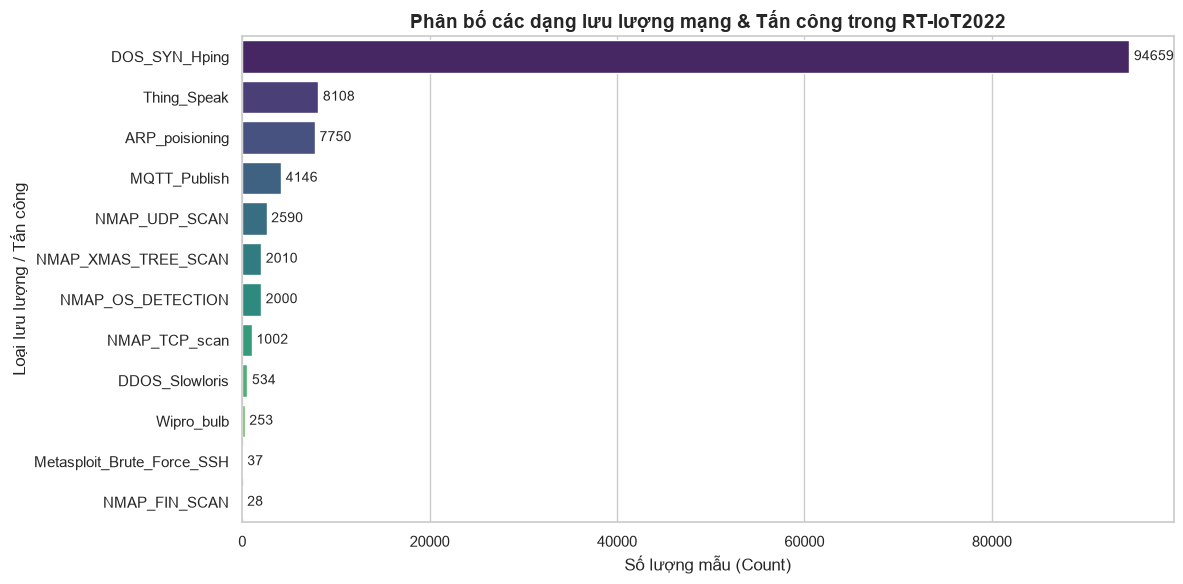

In [12]:
# Vẽ biểu đồ cột hiển thị tần suất của từng loại lưu lượng/tấn công
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=attack_counts.values,
    y=attack_counts.index,
    hue=attack_counts.index,
    palette='viridis',
    legend=False
)

plt.title('Phân bố các dạng lưu lượng mạng & Tấn công trong RT-IoT2022', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng mẫu (Count)')
plt.ylabel('Loại lưu lượng / Tấn công')

# Hiển thị số lượng chi tiết trên từng thanh
for i, v in enumerate(attack_counts.values):
    ax.text(v + 500, i, str(v), va='center', fontsize=10)

plt.tight_layout()

# Lưu hình vào thư mục figures
fig_path_1 = os.path.join(output_dir, 'attack_distribution.png')
plt.savefig(fig_path_1, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ vào: {fig_path_1}")

plt.show()

In [15]:
# Lựa chọn các biến dạng số
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Hiển thị tất cả các dòng kết quả, không giới hạn số dòng
pd.set_option('display.max_rows', None)

# Hiển thị các chỉ số thống kê cơ bản: mean, std, min, max, median (50%)
stats_df = df[numeric_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]

# Hiển thị toàn bộ bảng thống kê
display(stats_df)


,mean,std,min,50%,max
Unnamed: 0,3.703509e+04,3.045911e+04,0.0,3.310000e+04,9.465800e+04
id.orig_p,3.463926e+04,1.907062e+04,0.0,3.722100e+04,6.553500e+04
id.resp_p,1.014305e+03,5.256372e+03,0.0,2.100000e+01,6.538900e+04
flow_duration,3.809566e+00,1.300054e+02,0.0,4.000000e-06,2.172834e+04
fwd_pkts_tot,2.268826e+00,2.233656e+01,0.0,1.000000e+00,4.345000e+03
bwd_pkts_tot,1.909509e+00,3.301831e+01,0.0,1.000000e+00,1.011200e+04
fwd_data_pkts_tot,1.471218e+00,1.963520e+01,0.0,1.000000e+00,4.345000e+03
bwd_data_pkts_tot,8.202604e-01,3.229395e+01,0.0,0.000000e+00,1.010500e+04
fwd_pkts_per_sec,3.518063e+05,3.707645e+05,0.0,2.467238e+05,1.048576e+06
bwd_pkts_per_sec,3.517620e+05,3.708015e+05,0.0,2.467238e+05,1.048576e+06


In [21]:
# Chọn cột số, bỏ cột chỉ số
cot_so = df.select_dtypes(include=[np.number]).drop(columns=['Unnamed: 0'])

# Lấy giá trị tuyệt đối của hệ số tương quan
tuong_quan = cot_so.corr().abs()

# Giữ nửa tam giác trên để mỗi cặp chỉ xuất hiện một lần
nua_tren = tuong_quan.where(np.triu(np.ones(tuong_quan.shape), k=1).astype(bool))

# Liệt kê các cặp có hệ số lớn hơn 0.95
cap_cao = nua_tren.stack()
cap_cao = cap_cao[cap_cao > 0.95].sort_values(ascending=False)
print("Số cặp có |r| > 0.95:", len(cap_cao))
print(cap_cao.head(30))

# Lưu bảng làm minh chứng
cap_cao.to_csv(os.path.join(output_dir, 'cap_tuong_quan_cao.csv'))

Số cặp có |r| > 0.95: 52
flow_duration         flow_iat.tot                1.000000
bwd_pkts_per_sec      flow_pkts_per_sec           0.999997
fwd_pkts_per_sec      flow_pkts_per_sec           0.999997
                      bwd_pkts_per_sec            0.999986
bwd_bulk_bytes        bwd_bulk_packets            0.999802
flow_iat.max          idle.max                    0.999748
fwd_iat.tot           flow_iat.tot                0.999719
flow_duration         fwd_iat.tot                 0.999719
fwd_iat.max           flow_iat.max                0.996647
                      idle.max                    0.996389
idle.max              idle.avg                    0.995069
flow_duration         idle.tot                    0.995023
flow_iat.tot          idle.tot                    0.995023
flow_iat.max          idle.avg                    0.994813
fwd_iat.tot           idle.tot                    0.994715
bwd_pkts_payload.tot  flow_pkts_payload.tot       0.993704
bwd_pkts_tot          bwd_data_

Đã lưu biểu đồ vào: figures\flow_duration_boxplot.png


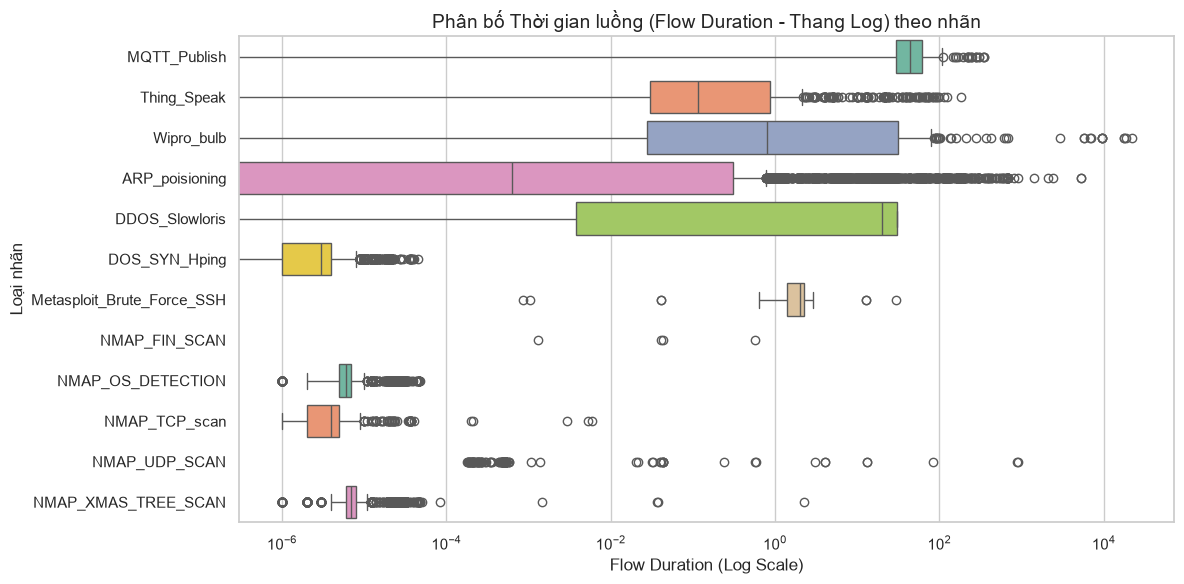

In [13]:
# Phân tích đặc trưng 'flow_duration' theo từng nhóm tấn công
if 'flow_duration' in df.columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(
    x='flow_duration',
    y=target_col,
    data=df,
    hue=target_col,
    palette='Set2',
    legend=False
)
    plt.xscale('log')  # Dùng thang đo Logarit vì khoảng giá trị thời gian chênh lệch lớn
    plt.title('Phân bố Thời gian luồng (Flow Duration - Thang Log) theo nhãn', fontsize=14)
    plt.xlabel('Flow Duration (Log Scale)')
    plt.ylabel('Loại nhãn')
    plt.tight_layout()

    # Lưu hình vào thư mục figures
    fig_path_2 = os.path.join(output_dir, 'flow_duration_boxplot.png')
    plt.savefig(fig_path_2, dpi=300, bbox_inches='tight')
    print(f"Đã lưu biểu đồ vào: {fig_path_2}")

    plt.show()

Đã lưu biểu đồ vào: figures\correlation_heatmap.png


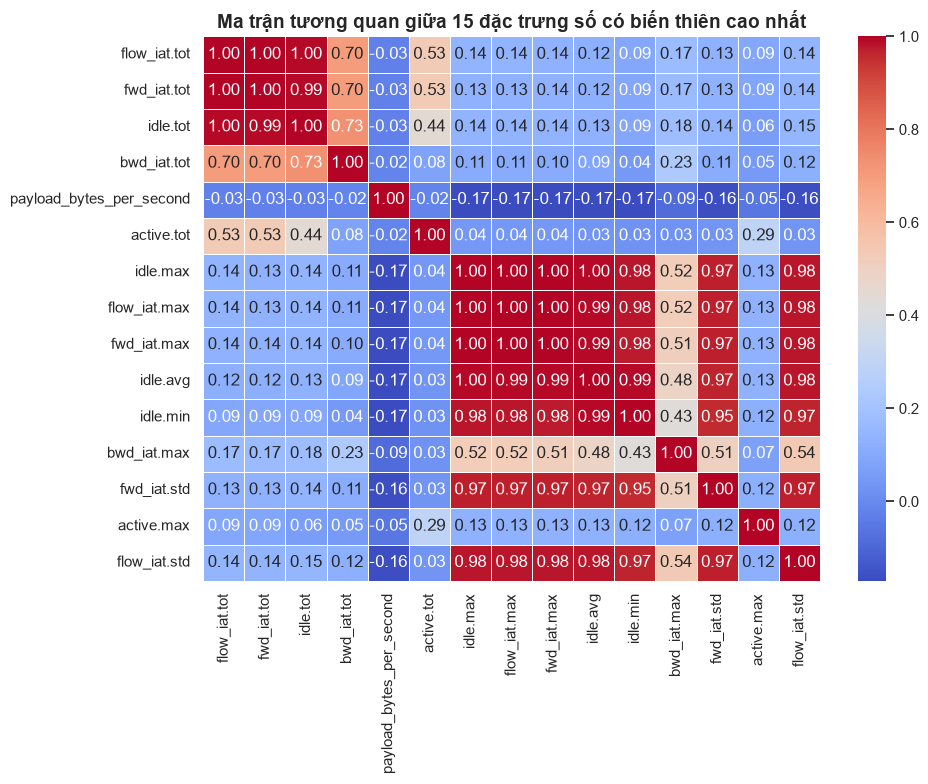

In [11]:
# Chọn top các đặc trưng số có độ biến thiên cao để xem tương quan
numeric_df = df[numeric_cols]
variance = numeric_df.var().sort_values(ascending=False)
top_features = variance.head(15).index.tolist()

plt.figure(figsize=(10, 8))
corr_matrix = numeric_df[top_features].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Ma trận tương quan giữa 15 đặc trưng số có biến thiên cao nhất', fontsize=14, fontweight='bold')
plt.tight_layout()

# Lưu hình vào thư mục figures
fig_path_3 = os.path.join(output_dir, 'correlation_heatmap.png')
plt.savefig(fig_path_3, dpi=300, bbox_inches='tight')
print(f"Đã lưu biểu đồ vào: {fig_path_3}")

plt.show()